In [158]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [1]:
data_path = "C:\\AI Equipment Failure Prediction\\data\\21_cmapss_fd001_sample.csv"
df = pd.read_csv(data_path)

NameError: name 'pd' is not defined

In [160]:
import matplotlib.pyplot as plt

# Windows 한글 글꼴 설정
plt.rcParams['font.family'] = 'Malgun Gothic'

# 음수 기호 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False

In [161]:
df.shape

(1031, 10)

In [162]:
df['unit_nr'].value_counts().sort_index()

unit_nr
1    192
2    287
3    179
4    218
5    155
Name: count, dtype: int64

In [163]:
engine1 = df[df['unit_nr'] == 1]

In [164]:
engine1.shape

(192, 10)

In [165]:
engine1.info()

<class 'pandas.DataFrame'>
RangeIndex: 192 entries, 0 to 191
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   unit_nr      192 non-null    int64  
 1   time_cycles  192 non-null    int64  
 2   setting_1    192 non-null    float64
 3   setting_2    192 non-null    float64
 4   setting_3    192 non-null    float64
 5   s_2          192 non-null    float64
 6   s_3          192 non-null    float64
 7   s_4          192 non-null    float64
 8   s_7          192 non-null    float64
 9   s_11         192 non-null    float64
dtypes: float64(8), int64(2)
memory usage: 15.1 KB


In [166]:
s2 = engine1['s_2']

In [167]:
s2.head()

0    640.69
1    641.13
2    641.25
3    641.97
4    641.58
Name: s_2, dtype: float64

In [168]:
ma = engine1['s_3'].rolling(20).mean()
sd = engine1['s_3'].rolling(20).std()

In [169]:
#실습4 s_4

In [170]:
e2 = df[df['unit_nr'] == 2]
e2.head()

,unit_nr,time_cycles,setting_1,setting_2,setting_3,s_2,s_3,s_4,s_7,s_11
192,2,1,0.0019,-0.0002,100.0,640.95,1585.27,1399.71,554.13,47.216
193,2,2,-0.0030,-0.0001,100.0,640.83,1585.76,1400.55,554.23,47.013
194,2,3,-0.0051,0.0002,100.0,640.17,1585.38,1398.30,553.76,47.043
195,2,4,0.0019,-0.0001,100.0,641.42,1585.18,1401.12,553.58,47.104
196,2,5,-0.0027,-0.0001,100.0,640.62,1585.38,1399.49,553.62,46.874


In [171]:
engine2['s_4']

192    1399.71
193    1400.55
194    1398.30
195    1401.12
196    1399.49
        ...   
474    1418.05
475    1416.95
476    1417.60
477    1416.41
478    1416.77
Name: s_4, Length: 287, dtype: float64

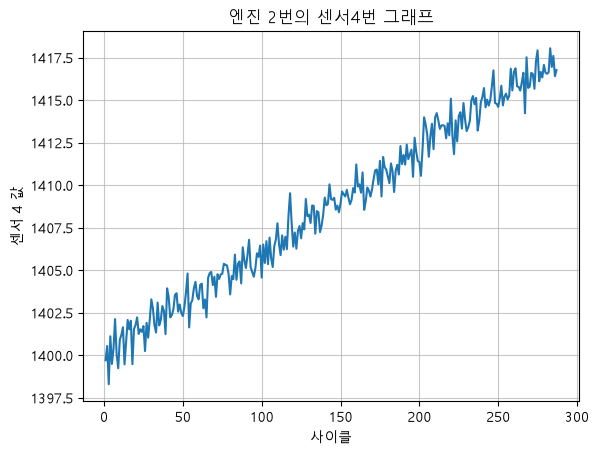

In [172]:
plt.plot(engine2['time_cycles'],engine2['s_4'])

plt.title('엔진 2번의 센서4번 그래프')
plt.xlabel('사이클')
plt.ylabel('센서 4 값')
plt.grid(True, alpha=0.7)

plt.show()

In [173]:
#실습2  s4

In [174]:
e2_roll = engine2['s_4'].rolling(window=10).mean()

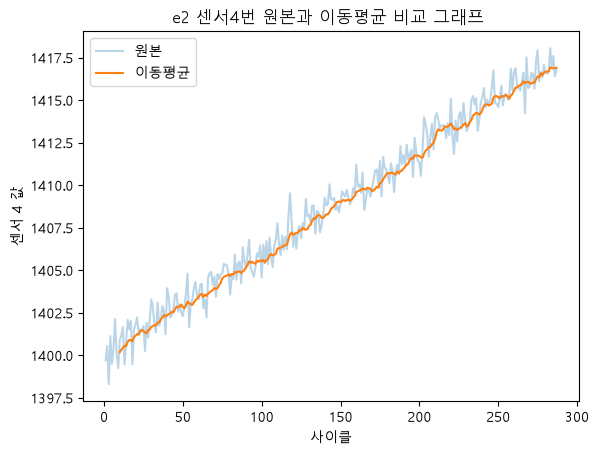

In [175]:
plt.plot(engine2['time_cycles'],engine2['s_4'], alpha=0.3)
plt.plot(engine2['time_cycles'], e2_roll)


plt.legend(['원본', '이동평균'])
plt.title('e2 센서4번 원본과 이동평균 비교 그래프 ')
plt.xlabel('사이클')
plt.ylabel('센서 4 값')

plt.show()

In [176]:
#실습3

In [177]:
#창  크기를  5·20·50으로  바꿔 이동평균계산


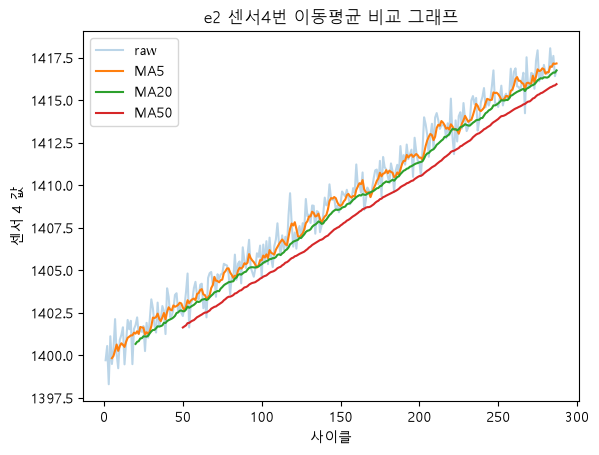

In [178]:
plt.plot(engine2['time_cycles'],engine2['s_4'], alpha=0.3, label='raw')

for window in [5, 20, 50]:
    e2_roll = engine2['s_4'].rolling(window=window).mean()
    plt.plot(engine2['time_cycles'], e2_roll, label=f'MA{window}')
plt.legend()
plt.title('e2 센서4번 이동평균 비교 그래프')
plt.xlabel('사이클')
plt.ylabel('센서 4 값')
plt.show()




In [179]:
#실습4
#'s_4', 's_7', 's_11

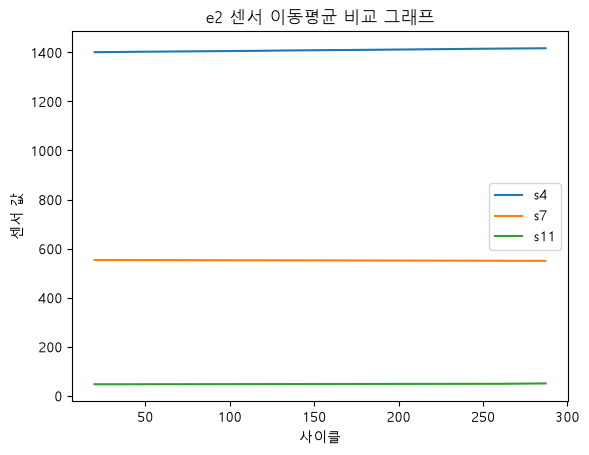

In [180]:
for sensor in [4, 7, 11]: #????
    e2_roll = engine2[f's_{sensor}'].rolling(window=20).mean()
    plt.plot(engine2['time_cycles'], e2_roll, label=f's{sensor}')
plt.legend()
plt.title('e2 센서 이동평균 비교 그래프')
plt.xlabel('사이클')
plt.ylabel('센서 값')
plt.show()

In [181]:
'a' if True else 'b'

'a'

In [182]:
'a' if False else 'b'

'b'

In [183]:
#실습5

In [184]:
std20 = e2['s_3'].rolling(window=20).std()

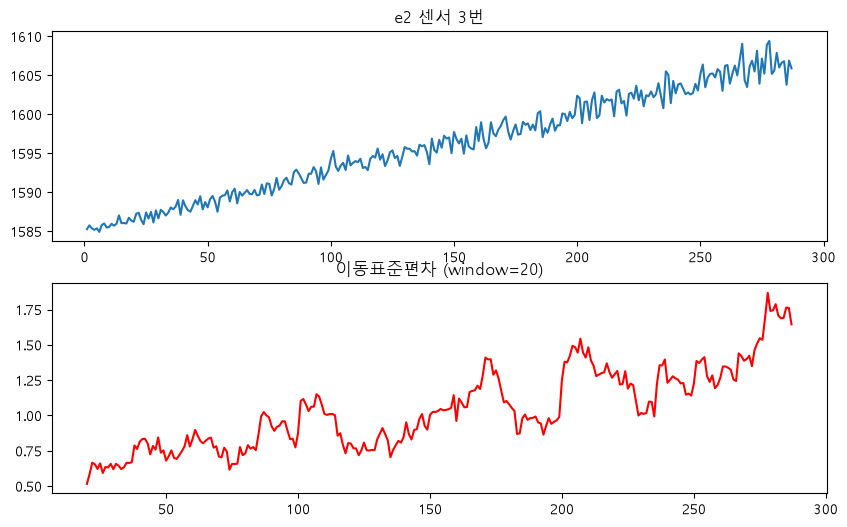

In [185]:
plt.figure(figsize=(10, 6))
# 첫 번째 그래프
plt.subplot(2, 1, 1)
plt.title('e2 센서 3번')
plt.plot(e2['time_cycles'], e2['s_3'])

# 두 번째 그래프
plt.subplot(2, 1, 2)
plt.title('이동표준편차 (window=20)')
plt.plot(e2['time_cycles'], std20, color='r')


In [186]:

plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

In [187]:
type(res[0])

matplotlib.lines.Line2D

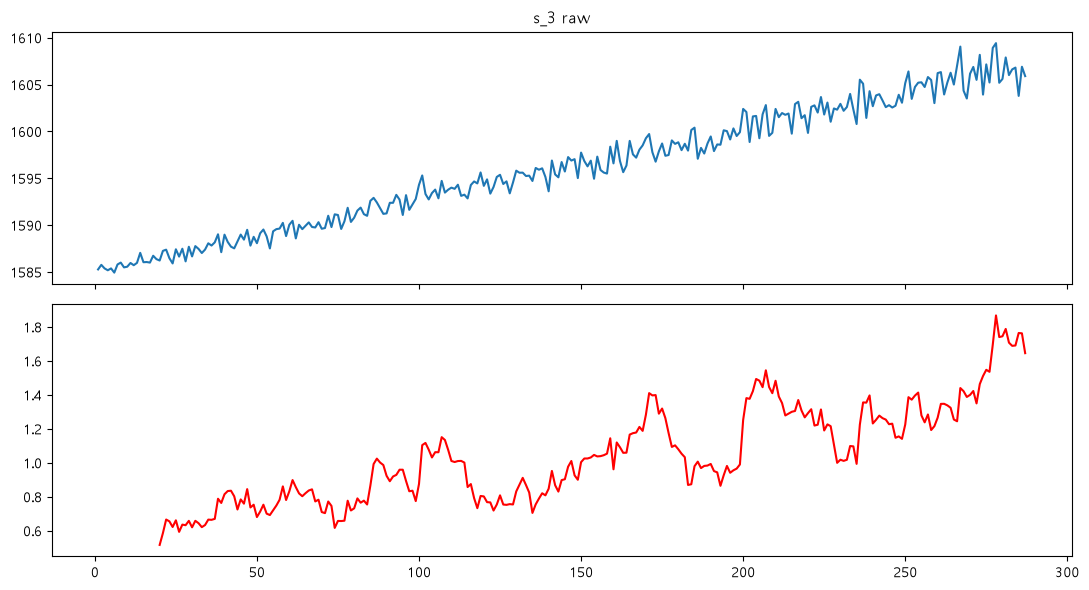

In [188]:
std20 = e2['s_3'].rolling(window=20).std()
fig, (ax1, ax2) = plt.subplots(2, 1,figsize=(11, 6), sharex=True)

ax1.plot(e2['time_cycles'], e2['s_3']); ax1.set_title('s_3 raw')
ax2.plot(e2['time_cycles'], std20, color='r')


plt.tight_layout()
plt.show()

In [189]:
#실습6

In [190]:
sd = e2['s_3'].rolling(window=20).std()

In [191]:
ma = e2['s_3'].rolling(20).mean()

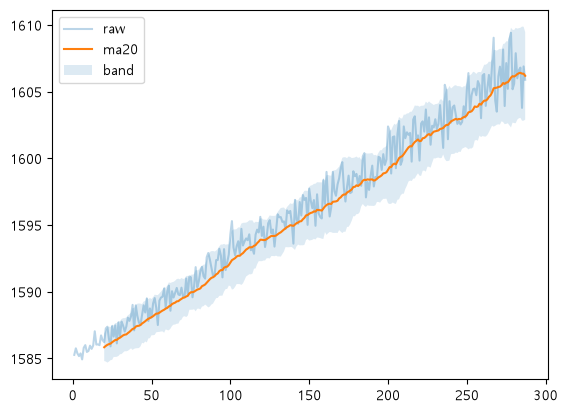

In [192]:
plt.plot(e2['time_cycles'], e2['s_3'], alpha=0.3, label='raw')
plt.plot(e2['time_cycles'], ma, label='ma20')

plt.fill_between(e2['time_cycles'], 
                 ma - 2*sd, ma + 2*sd, alpha=0.15, label='band')

plt.legend()
plt.show()


In [193]:
ma - 2*sd, ma + 2*sd

(192            NaN
 193            NaN
 194            NaN
 195            NaN
 196            NaN
           ...     
 474    1603.014823
 475    1603.037877
 476    1602.830362
 477    1602.828797
 478    1602.904994
 Name: s_3, Length: 287, dtype: float64,
 192            NaN
 193            NaN
 194            NaN
 195            NaN
 196            NaN
           ...     
 474    1609.768177
 475    1609.800123
 476    1609.886638
 477    1609.877203
 478    1609.486006
 Name: s_3, Length: 287, dtype: float64)

In [194]:
#실습7
#s2 s3 s11 

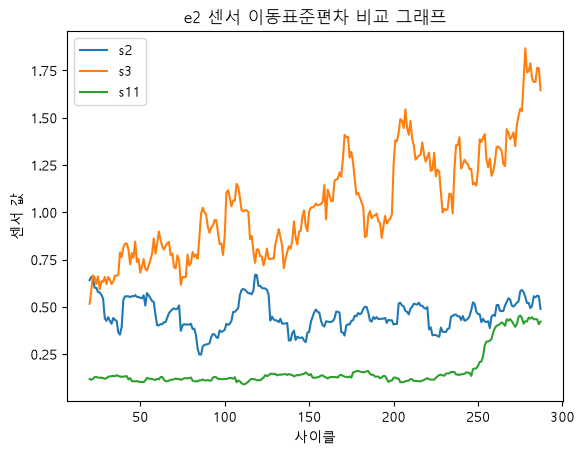

In [195]:
for sensor in [2, 3, 11]: #????
    e2_roll = engine2[f's_{sensor}'].rolling(window=20).std()
    plt.plot(engine2['time_cycles'], e2_roll, label=f's{sensor}')
plt.legend()
plt.title('e2 센서 이동표준편차 비교 그래프')
plt.xlabel('사이클')
plt.ylabel('센서 값')
plt.show()

In [196]:
abel=f's{sensor}')

SyntaxError: unmatched ')' (3336535231.py, line 1)

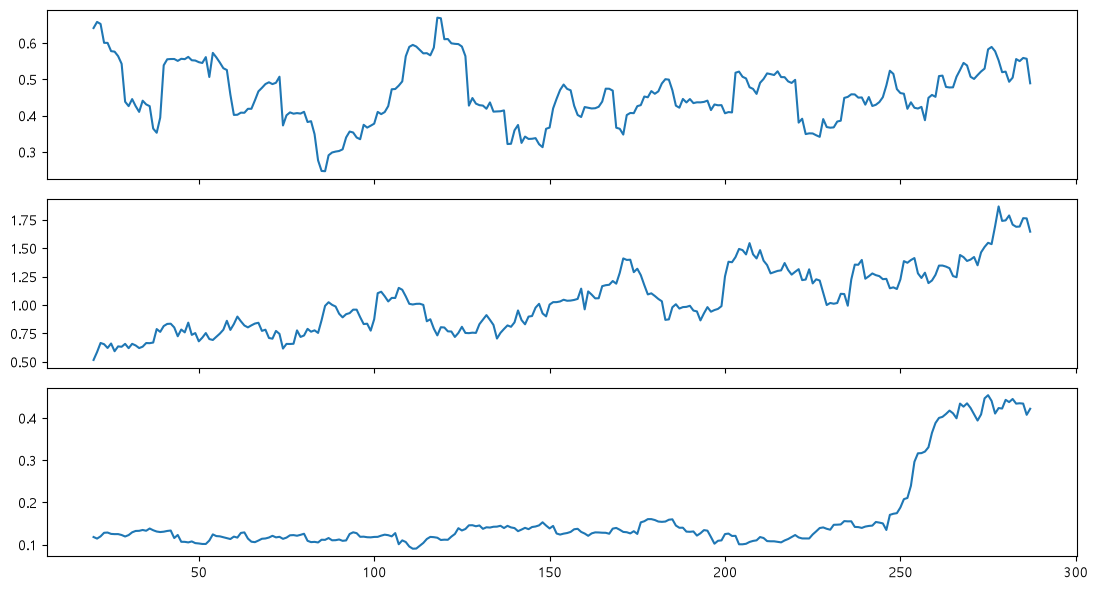

In [ ]:
fig, (ax1, ax2, ax3) = plt.subplots(3, 1,figsize=(11, 6), sharex=True)

for ax, sensor in zip([ax1, ax2, ax3], ['s_2', 's_3', 's_11']):
    e2_roll = e2[sensor].rolling(window=20).std()
    ax.plot(e2['time_cycles'], e2_roll)

plt.tight_layout()
plt.show()

In [ ]:
's_2': 's_2_저압압축기출구온도',
's_3': 's_3_고압압축기출구온도',
's_11': 's_11_고압압축기출구정압',

In [ ]:
#21_02
#21_03  진행예정

In [ ]:
s = pd.Series([100, 103, 102, 108, 107])
print(s.diff().to_list())

print((s.pct_change() * 100).round(2).to_list())  # 백분율 변화

[nan, 3.0, -1.0, 6.0, -1.0]
[nan, 3.0, -0.97, 5.88, -0.93]


In [ ]:
s = pd.Series([100, 103, 102, 108, 107])
print(s.diff(2).to_list())

[nan, nan, 2.0, 5.0, 5.0]


In [ ]:
#실습1

In [157]:
e2.head()

,unit_nr,time_cycles,setting_1,setting_2,setting_3,s_2,s_3,s_4,s_7,s_11
192,2,1,0.0019,-0.0002,100.0,640.95,1585.27,1399.71,554.13,47.216
193,2,2,-0.0030,-0.0001,100.0,640.83,1585.76,1400.55,554.23,47.013
194,2,3,-0.0051,0.0002,100.0,640.17,1585.38,1398.30,553.76,47.043
195,2,4,0.0019,-0.0001,100.0,641.42,1585.18,1401.12,553.58,47.104
196,2,5,-0.0027,-0.0001,100.0,640.62,1585.38,1399.49,553.62,46.874


In [197]:
e2_diff = e2.diff()

In [198]:
e2_diff.head()

,unit_nr,time_cycles,setting_1,setting_2,setting_3,s_2,s_3,s_4,s_7,s_11
192,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
193,0.0,1.0,-0.0049,0.0001,0.0,-0.12,0.49,0.84,0.10,-0.203
194,0.0,1.0,-0.0021,0.0003,0.0,-0.66,-0.38,-2.25,-0.47,0.030
195,0.0,1.0,0.0070,-0.0003,0.0,1.25,-0.20,2.82,-0.18,0.061
196,0.0,1.0,-0.0046,0.0000,0.0,-0.80,0.20,-1.63,0.04,-0.230


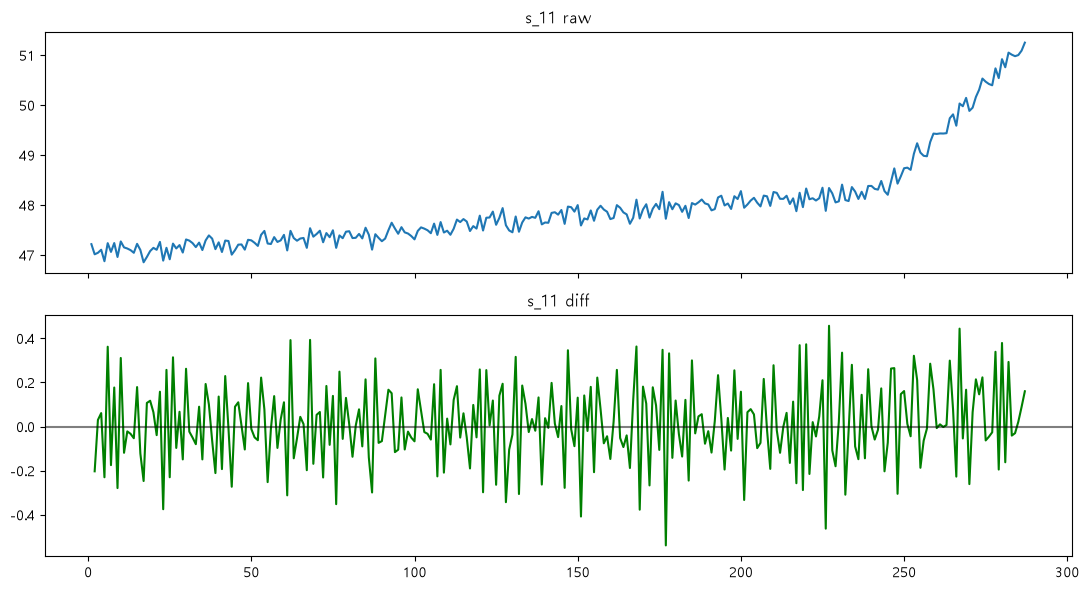

In [212]:
fig, (ax1, ax2) = plt.subplots(2, 1,figsize=(11, 6), sharex=True)

ax1.plot(e2['time_cycles'], e2['s_11']); ax1.set_title('s_11 raw')
ax2.plot(e2['time_cycles'], e2_diff['s_11'], color='g'); ax2.set_title('s_11 diff')
ax2.axhline(0, color='black', alpha=0.5)

plt.tight_layout()
plt.show()

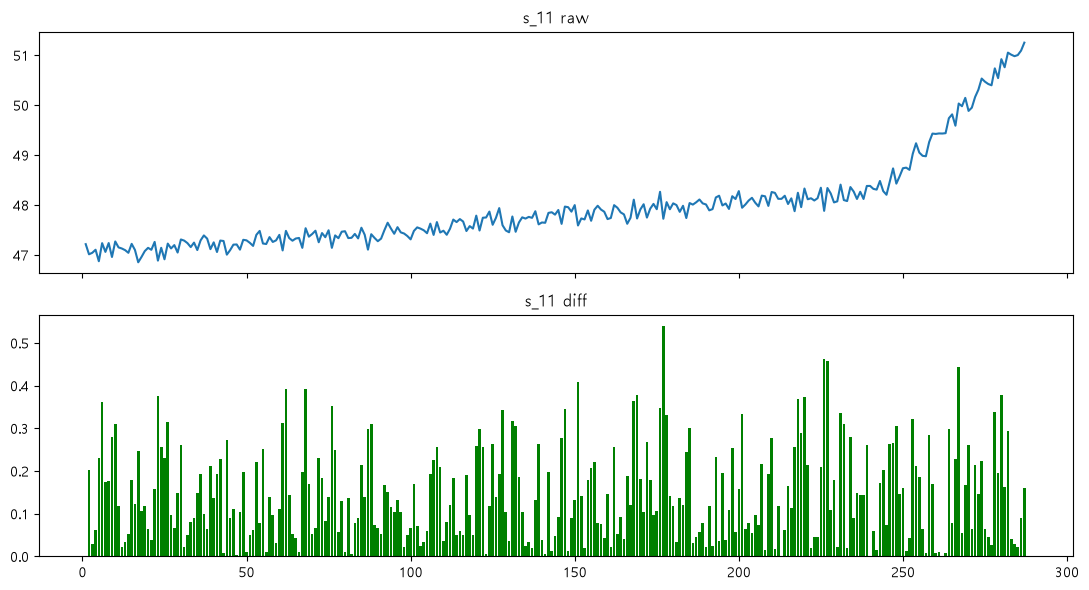

In [219]:
fig, (ax1, ax2) = plt.subplots(2, 1,figsize=(11, 6), sharex=True)

ax1.plot(e2['time_cycles'], e2['s_11']); ax1.set_title('s_11 raw')
ax2.bar(e2['time_cycles'], abs(e2_diff['s_11']), color='g'); ax2.set_title('s_11 diff')

plt.tight_layout()
plt.show()

In [221]:
#실습2 엔진 2 s3

In [223]:
e2['s_3']

192    1585.27
193    1585.76
194    1585.38
195    1585.18
196    1585.38
        ...   
474    1606.62
475    1606.81
476    1603.79
477    1606.90
478    1605.90
Name: s_3, Length: 287, dtype: float64

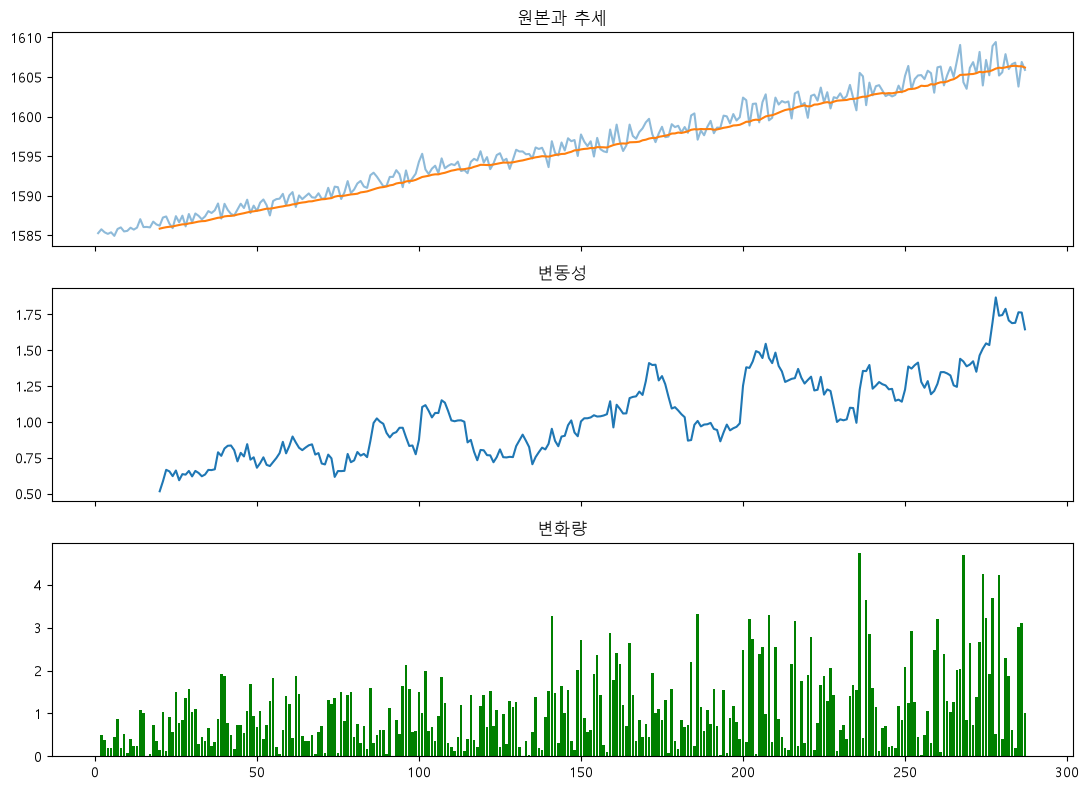

In [236]:
e2_MA=e2['s_3'].rolling(20).mean()
e2_std = e2['s_3'].rolling(20).std()
e2_diff = e2['s_3'].diff()

fig,(ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(11, 8), sharex=True)

ax1.plot(e2['time_cycles'], e2['s_3'], alpha=0.5)
ax1.plot(e2['time_cycles'], e2_MA); ax1.set_title('원본과 추세')
ax2.plot(e2['time_cycles'], e2_std); ax2.set_title('변동성')
ax3.bar(e2['time_cycles'], abs(e2_diff), color='g'); ax3.set_title('변화량')
plt.tight_layout();plt.show()


In [231]:
#추세는  완만한  상승 , 변동성 ·변화량은  후반에  커지는  신호

In [ ]:
#실습3 s_4

In [283]:
tss = "C:\\AI Equipment Failure Prediction\\data\\21_engine1_timestamp_sample.csv"
ts = pd.read_csv(tss)

In [268]:
df.columns.to_list()

['timestamp', 's_2', 's_3', 's_4', 's_7', 's_11']

In [270]:
df['timestamp'] = pd.to_datetime(df['timestamp'], format='%Y-%m-%d %H:%M:%S')

In [271]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 192 entries, 0 to 191
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   timestamp  192 non-null    datetime64[us]
 1   s_2        192 non-null    float64       
 2   s_3        192 non-null    float64       
 3   s_4        192 non-null    float64       
 4   s_7        192 non-null    float64       
 5   s_11       192 non-null    float64       
dtypes: datetime64[us](1), float64(5)
memory usage: 9.1 KB


In [274]:
df.set_index('timestamp', inplace=True)
df.head()

,s_2,s_3,s_4,s_7,s_11
timestamp,,,,,
2024-01-01 00:00:00,640.69,1585.21,1399.30,554.17,46.931
2024-01-01 01:00:00,641.13,1585.55,1401.18,554.36,46.857
2024-01-01 02:00:00,641.25,1584.72,1400.84,554.00,47.220
2024-01-01 03:00:00,641.97,1585.94,1401.26,554.13,47.152
2024-01-01 04:00:00,641.58,1585.72,1401.36,553.87,46.956


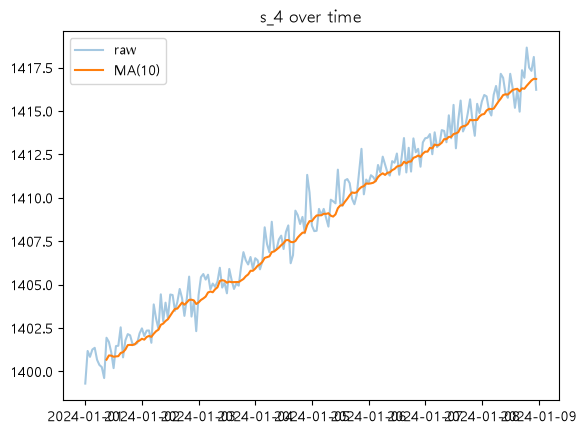

In [ ]:
plt.plot(df.index, df['s_4'], alpha=0.4, label='raw')
plt.plot(df.index, df['s_4'].rolling(10).mean(), label='MA(10)')
plt.title('s_4 over time')
plt.legend()
plt.show()

In [284]:
#실습4 ts s4

In [294]:
ts.head()

,s_2,s_3,s_4,s_7,s_11
timestamp,,,,,
2024-01-01 00:00:00,640.69,1585.21,1399.30,554.17,46.931
2024-01-01 01:00:00,641.13,1585.55,1401.18,554.36,46.857
2024-01-01 02:00:00,641.25,1584.72,1400.84,554.00,47.220
2024-01-01 03:00:00,641.97,1585.94,1401.26,554.13,47.152
2024-01-01 04:00:00,641.58,1585.72,1401.36,553.87,46.956


In [299]:
# ts의 인덱스를 날짜·시간 형식으로 변환
ts.index = pd.to_datetime(ts.index)

six_hour = ts['s_4'].resample('6h').mean()
day = ts['s_4'].resample('D').mean()

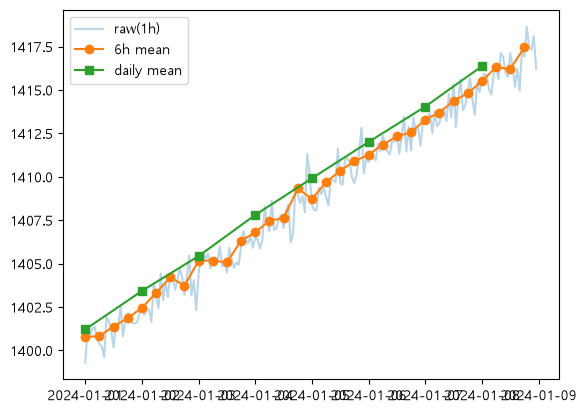

하루  평균  개수 : 8


In [301]:
plt.plot(ts.index, ts['s_4'], alpha=0.3, label='raw(1h)')
plt.plot(six_hour.index, six_hour, marker='o', label='6h mean')
plt.plot(day.index, day, marker='s', label='daily mean')
plt.legend(); plt.show()
print('하루  평균  개수 :', len(day))  

In [304]:
from statsmodels.tsa.seasonal import seasonal_decompose

In [305]:
# 실습5

In [306]:
s = pd.Series([10.0 , np.nan , np.nan , 16,0, 18,0])

In [308]:
sff = s.ffill()
sff

0    10.0
1    10.0
2    10.0
3    16.0
4     0.0
5    18.0
6     0.0
dtype: float64

In [309]:
sbf = s.bfill()
sbf

0    10.0
1    16.0
2    16.0
3    16.0
4     0.0
5    18.0
6     0.0
dtype: float64

In [310]:
sint = s.interpolate()
sint

0    10.0
1    12.0
2    14.0
3    16.0
4     0.0
5    18.0
6     0.0
dtype: float64

In [ ]:

# from statsmodels.tsa.seasonal import seasonal_decompose

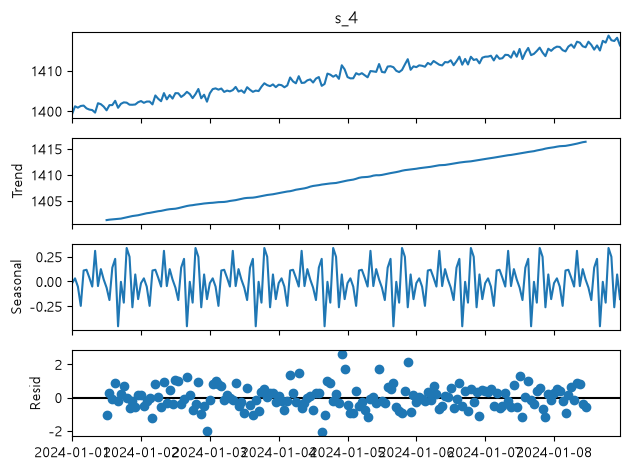

In [311]:
seasonal_decompose(ts['s_4'], model='additive', period=24).plot()
plt.show()

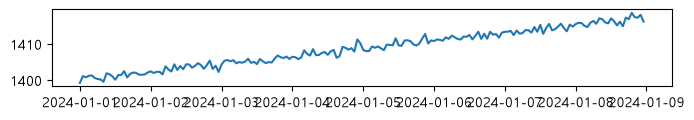

In [319]:
plt.figure(figsize=(8, 1))
plt.plot(ts.index, ts['s_4'])
plt.show()

In [320]:
result = seasonal_decompose(ts['s_4'])

In [321]:
result.observed

timestamp
2024-01-01 00:00:00    1399.30
2024-01-01 01:00:00    1401.18
2024-01-01 02:00:00    1400.84
2024-01-01 03:00:00    1401.26
2024-01-01 04:00:00    1401.36
                        ...   
2024-01-08 19:00:00    1418.65
2024-01-08 20:00:00    1417.50
2024-01-08 21:00:00    1417.31
2024-01-08 22:00:00    1418.11
2024-01-08 23:00:00    1416.22
Name: s_4, Length: 192, dtype: float64

In [324]:
result.trend.notna().sum()

np.int64(168)

In [326]:
result_df[result.trend.notna()]

NameError: name 'result_df' is not defined

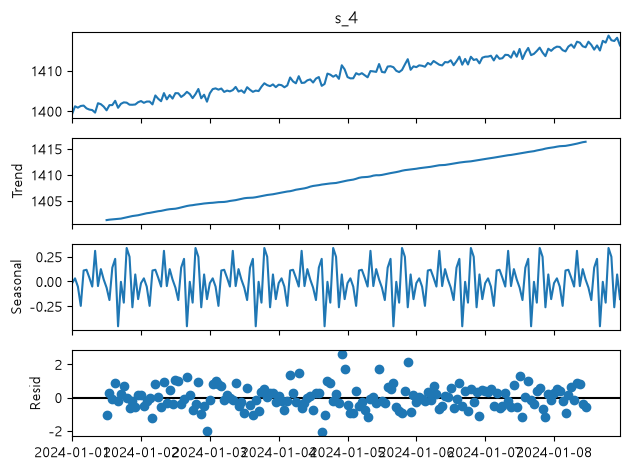

In [315]:
seasonal_decompose(ts['s_4']).plot()

plt.show()